In [1]:

import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.load_data import load_raw_data
from src.clean_data import clean_data
from src.analysis import numerical_summary


df = load_raw_data("../data/raw/yellow_tripdata_2026-01.parquet")
zones = pd.read_csv("../data/raw/taxi_zone_lookup.csv")

df = df.merge(zones, left_on="PULocationID", right_on="LocationID", how="left")
df = df.rename(columns={"Zone": "pickup_zone", "Borough": "pickup_borough"})
df = df.drop(columns=["LocationID", "service_zone"])
df = df.merge(zones, left_on="DOLocationID", right_on="LocationID", how="left")
df = df.rename(columns={"Zone": "dropoff_zone", "Borough": "dropoff_borough"})
df = df.drop(columns=["LocationID", "service_zone"])

df = clean_data(df)
print(f"df loaded: {len(df)} rows")

before cleaning len is  3724889
2026-09-27 19:56:35,682 | INFO     | src.clean_data | columns cleaned 
2026-09-27 19:56:35,716 | INFO     | src.clean_data | drop duplicated function is hit
the rows are reduced from 3724889 to 3724889
2026-09-27 19:56:57,093 | INFO     | src.clean_data | dates are swapped 
2026-09-27 19:56:57,106 | INFO     | src.clean_data | cleaning of tip, extra, toll, and tax amounts
2026-09-27 19:56:58,790 | INFO     | src.clean_data | the amount is replaced correctly
2026-09-27 19:56:58,804 | INFO     | src.clean_data | trip_duration column is added for future use
2026-09-27 19:56:59,254 | INFO     | src.clean_data | cleaning the outliers from amounts
2026-09-27 19:57:11,492 | INFO     | src.clean_data | cleaning trip_distance
after cleaning length is  3598437
df loaded: 3598437 rows


In [4]:

import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.load_data import load_raw_data
from src.clean_data import clean_data
from src.analysis import numerical_summary



df = load_raw_data("../data/raw/yellow_tripdata_2026-01.parquet")
zones = pd.read_csv("../data/raw/taxi_zone_lookup.csv")

df = df.merge(zones, left_on="PULocationID", right_on="LocationID", how="left")
df = df.rename(columns={"Zone": "pickup_zone", "Borough": "pickup_borough"})
df = df.drop(columns=["LocationID", "service_zone"])
df = df.merge(zones, left_on="DOLocationID", right_on="LocationID", how="left")
df = df.rename(columns={"Zone": "dropoff_zone", "Borough": "dropoff_borough"})
df = df.drop(columns=["LocationID", "service_zone"])

df = clean_data(df)
print("data after cleaning")
print(df.head(3))
print(f"df loaded: {len(df)} rows")

the rows are reduced from 3724889 to 3724889
data after cleaning
   vendorid tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2  2026-01-01 00:54:04   2026-01-01 00:59:37              1.0   
1         1  2026-01-01 00:34:04   2026-01-01 00:39:47              0.0   
2         1  2026-01-01 00:57:06   2026-01-01 01:05:59              0.0   

   trip_distance  ratecodeid store_and_fwd_flag  pulocationid  dolocationid  \
0           0.97         1.0                  N           239           238   
1           0.90         1.0                  N           163           162   
2           1.40         1.0                  N            43           237   

   payment_type  ...  improvement_surcharge  total_amount  \
0             1  ...                    1.0         15.86   
1             2  ...                    1.0         16.90   
2             1  ...                    1.0         22.20   

   congestion_surcharge  airport_fee  cbd_congestion_fee  pickup_borough

count    2.603210e+06
mean     1.254724e+00
std      6.671500e-01
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      8.000000e+00
Name: passenger_count, dtype: float64


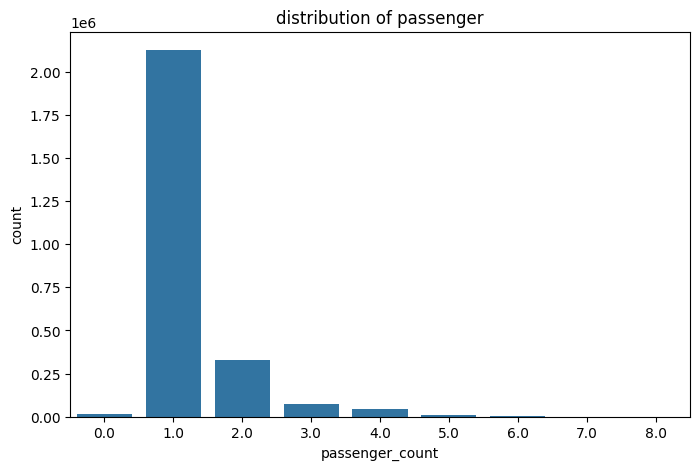

In [2]:
#passener analysis
print(df["passenger_count"].describe())
plt.figure(figsize=(8,5))
sns.countplot(x="passenger_count",data=df)
plt.title("distribution of passenger")
plt.show()

count    3.598437e+06
mean     3.487280e+00
std      4.284179e+00
min      1.000000e-02
25%      1.080000e+00
50%      1.900000e+00
75%      3.870000e+00
max      2.959900e+02
Name: trip_distance, dtype: float64
total trip_distnace with 0.01 is  vendorid                 19060
tpep_pickup_datetime     19060
tpep_dropoff_datetime    19060
passenger_count           2645
trip_distance            19060
ratecodeid                2645
store_and_fwd_flag        2645
pulocationid             19060
dolocationid             19060
payment_type             19060
fare_amount              19060
extra                    19060
mta_tax                  19060
tip_amount               19060
tolls_amount             19060
improvement_surcharge    19060
total_amount             19060
congestion_surcharge      2645
airport_fee               2645
cbd_congestion_fee       19060
pickup_borough           19031
pickup_zone              19057
dropoff_borough          19011
dropoff_zone             19045
trip_durat

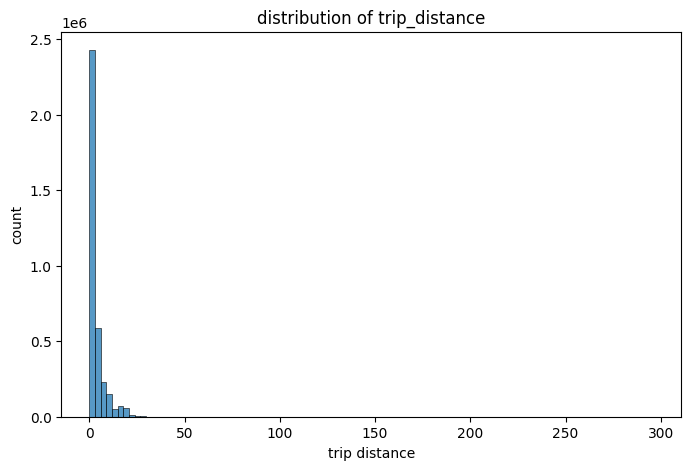

In [ ]:
#trip distance analysis
print(df["trip_distance"].describe())
ans=df.loc[df["trip_distance"]==0.01]
print("total trip_distnace with 0.01 is ",ans.count())
plt.figure(figsize=(8,5))
sns.histplot(df["trip_distance"],bins=10)
plt.title("distribution of trip_distance")
plt.xlabel("trip distance")
plt.ylabel("count")


plt.show()

count    3.598437e+06
mean     2.946051e+01
std      2.149550e+01
min     -9.995000e+01
25%      1.756000e+01
50%      2.340000e+01
75%      3.385000e+01
max      4.992100e+02
Name: total_amount, dtype: float64


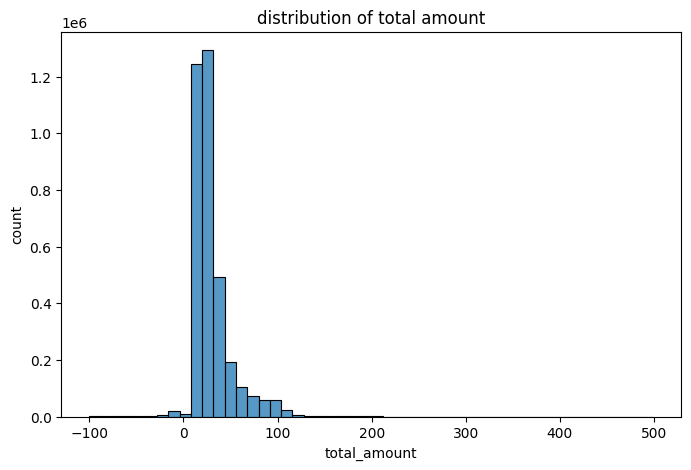

In [7]:
print(df["total_amount"].describe())
plt.figure(figsize=(8,5))
sns.histplot(df["total_amount"],bins=50)
plt.title("distribution of total amount")
plt.xlabel("total_amount")
plt.ylabel("count")
plt.show()

In [8]:
numerical_cols=["passenger_count","trip_distance","total_amount"]
summary=df[numerical_cols].describe().T
summary['median']=df[numerical_cols].median()
summary["iqr"]=summary["75%"]-summary["25%"]
summary["skewness"]=df[numerical_cols].skew()
summary["kurtosis"]=df[numerical_cols].kurt()
print("summary of numerical data",summary)


summary of numerical data                      count       mean        std    min    25%   50%    75%  \
passenger_count  2603210.0   1.254724   0.667150   0.00   1.00   1.0   1.00   
trip_distance    3598437.0   3.487280   4.284179   0.01   1.08   1.9   3.87   
total_amount     3598437.0  29.460512  21.495499 -99.95  17.56  23.4  33.85   

                    max  median    iqr  skewness   kurtosis  
passenger_count    8.00     1.0   0.00  3.156667  12.099608  
trip_distance    295.99     1.9   2.79  3.212755  29.334951  
total_amount     499.21    23.4  16.29  2.672329  19.176952  


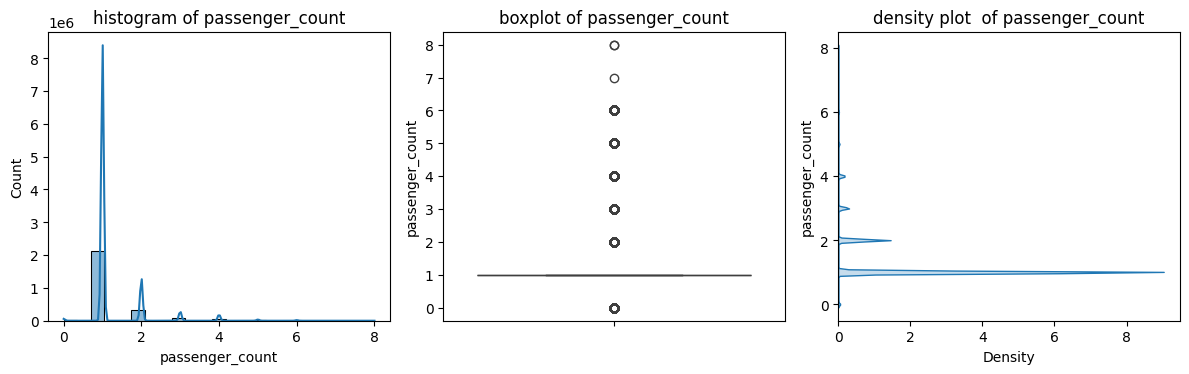

In [ ]:
numerical_cols=["passenger_count","trip_distance","total_amount"]
for cols in numerical_cols:
        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1)
        sns.histplot(df[cols],kde=True)
        plt.title(f"histogram of {cols}")

        plt.subplot(1,3,2)
        sns.boxplot(y=df[cols])
        plt.title(f"boxplot of {cols}")

        plt.subplot(1,3,3)
        sns.kdeplot(y=df[cols],fill=True)
        plt.title(f"density plot  of {cols}")
        plt.tight_layout()
        plt.show()

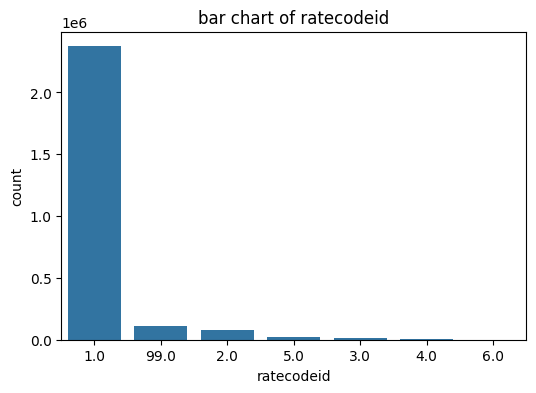

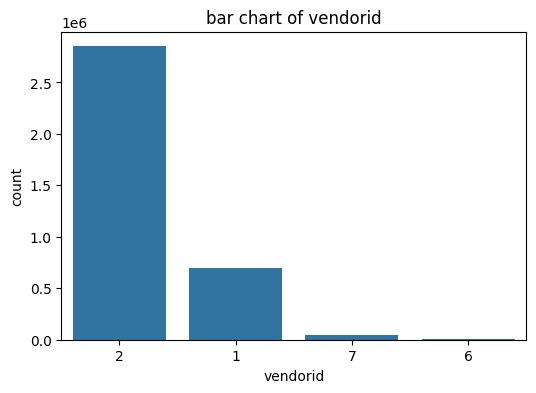

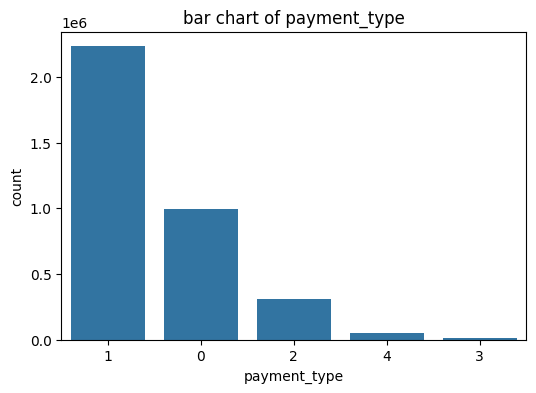

In [ ]:
cat_cols=["ratecodeid","vendorid","payment_type"]
for cols in cat_cols:
        plt.figure(figsize=(6,4))
        sns.countplot(x=cols,data=df,order=df[cols].value_counts().index)
        plt.title(f"bar chart of {cols}")
        plt.show()

In [ ]:

sample=df.sample(20000,random_state=42)
plt.figure(figsize=(8,5))
plt.subplot(1,3,1)
sns.scatterplot(x="trip_distance",y="total_amount",data=sample,alpha=0.1)
plt.title("trip distance vs total_amount")
print(df[["trip_distance","total_amount"]].corr())#this always defualt to pearson's correlation which may not be correct always


plt.subplot(1,3,2)
sns.scatterplot(x="passenger_count",y="total_amount",data=sample,alpha=0.1)
plt.title("passenger counts vs total amounts")
print(df[["passenger_count","total_amount"]].corr())

plt.subplot(1,3,3)
sns.scatterplot(x="passenger_count",y="trip_distance",data=sample,alpha=0.1)
plt.title("passenger count vs trip distance")
print(df[["passenger_count","trip_distance"]].corr())

0


In [ ]:

bi_cals=["payment_type","pickup_hour","pickup_dayofweek"]
target="total_amount"
for cols in bi_cals:
    plt.figure(figsize=(14, 4))

        # boxplot: distribution of target across categories
    plt.subplot(1, 3, 1)
    sns.boxplot(x=cols, y=target, data=df)
    plt.title(f"{target} by {cols}")
    plt.xticks(rotation=45)

        # barplot: mean of target per category
    plt.subplot(1, 3, 2)
    sns.barplot(x=cols, y=target, data=df, estimator="mean", errorbar=None)
    plt.title(f"mean {target} by {cols}")
    plt.xticks(rotation=45)

        # countplot: frequency of each category
    plt.subplot(1, 3, 3)
    sns.countplot(x=cols, data=df)
    plt.title(f"count of {cols}")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

        # quick numeric summary per category
    print(f"\nsummary of {target} grouped by {cols}")
    print(df.groupby(cols)[target].agg(["mean", "median", "std", "count"]))

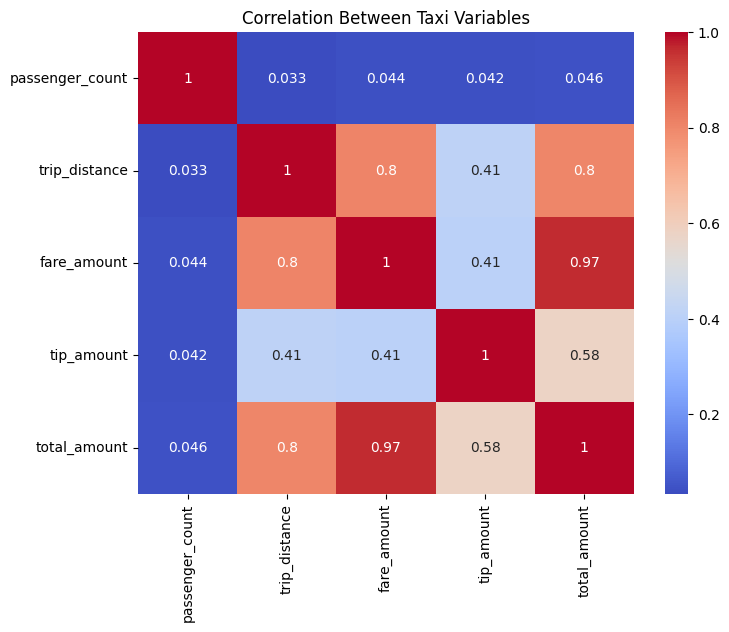

In [8]:
num_cols = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount"
]

corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Between Taxi Variables")
plt.show()

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="pickup_hour",y="trip_distance")
plt.xlabel("pickup_hour")
plt.ylable("trip_distance")
plt.show()

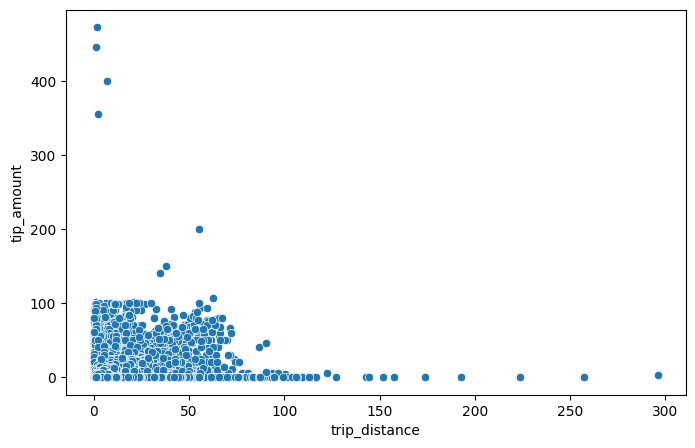

In [ ]:
#trip _distance vs tip_amount analysis
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="trip_distance",y="tip_amount")
plt.xlabel("trip_distance")
plt.ylabel("tip_amount")
plt.show()